In [1]:
%gui asyncio

In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

from clustering.utils import SpaceTimeSVD

from tqdm import tqdm
import pygpcca

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 22.3.6


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
import tifffile

In [4]:
frame = tifffile.imread("/home/kushal/lab/datasets/adam_cohen/2/230319PP071_cre_30x_P17_Cell1_D2.tiff")
movie = np.memmap("/home/kushal/lab/datasets/adam_cohen/2/frames.bin", dtype=np.uint16)

xdim, ydim = frame.shape
nframes = movie.size / (xdim * ydim)
assert nframes.is_integer()
nframes = int(nframes)

border_trim = 10

movie = movie.reshape(nframes, xdim, ydim)[100:1_000, border_trim:-border_trim, border_trim:-border_trim].astype(np.float32)

In [5]:
movie -= movie.mean(axis=0)

In [6]:
movie.shape

(900, 164, 884)

In [7]:
%matplotlib inline

In [8]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
iw_movie.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


The surface texture is suboptimal.
Suboptimal present of frame 2
The surface texture is suboptimal.
Suboptimal present of frame 0
The surface texture is suboptimal.
Suboptimal present of frame 2
The surface texture is suboptimal.
Suboptimal present of frame 1
The surface texture is suboptimal.
Suboptimal present of frame 0
The surface texture is suboptimal.
Suboptimal present of frame 2
The surface texture is suboptimal.
Suboptimal present of frame 1
The surface texture is suboptimal.
Suboptimal present of frame 2
The surface texture is suboptimal.
Suboptimal present of frame 1
The surface texture is suboptimal.
Suboptimal present of frame 0
The surface texture is suboptimal.
Suboptimal present of frame 1
The surface texture is suboptimal.
Suboptimal present of frame 0
The surface texture is suboptimal.
Suboptimal present of frame 1
The surface texture is suboptimal.
Suboptimal present of frame 0
The surface texture is suboptimal.
Suboptimal present of frame 0
The surface texture is su

In [9]:
iw_movie.window_funcs = {"t": (np.mean, 7)}

In [10]:
iw = fpl.ImageWidget(movie.std(axis=0), cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
rs = iw.managed_graphics[0].add_rectangle_selector()
iw.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
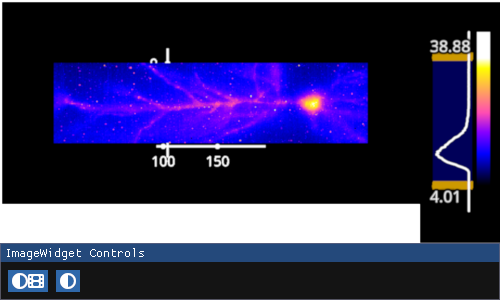

In [14]:
rows, cols = rs.get_selected_indices()
sub = movie[:, rows[0]:rows[-1]:2, cols[0]:cols[-1]:2]
iw_movie = fpl.ImageWidget(sub.std(axis=0), cmap="gnuplot2")
iw_movie.show()

In [13]:
rs.limits = (0, 884, 0, 164)

In [16]:
sub = sub[:, ::2, ::2]

In [17]:
sub.shape

(900, 37, 145)

In [18]:
series = sub.reshape(sub.shape[0], sub.shape[1] * sub.shape[2]).T
series.shape

(5365, 900)

In [19]:
B = series @ series.T

In [20]:
B.min()

np.float32(-75349.14)

In [24]:
series.min()

np.float32(-130.04889)

In [34]:
B = np.abs((B + B.T) / 2)

In [35]:
B.shape

(5365, 5365)

In [36]:
d = 1.0 / np.sum(B.astype(np.float64), axis=0)

In [37]:
a = np.diag(d) @ B

RFBOutputContext()

JupyterWgpuCanvas()
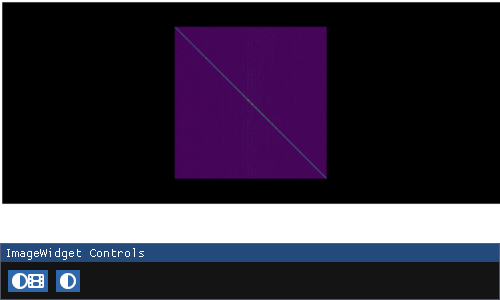

In [38]:
iw_s = fpl.ImageWidget(a, cmap="viridis", histogram_widget=False)
iw_s.show()

In [39]:
a.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

In [40]:
import pygpcca as gp

In [41]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

In [42]:
mc = gpcca.minChi(10, 20)

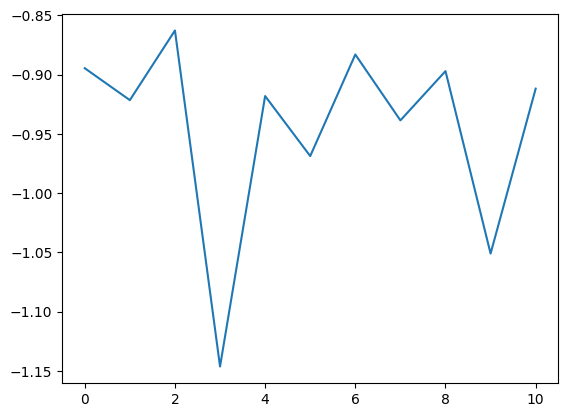

In [43]:
plt.plot(mc)

In [44]:
mc

[np.float64(-0.8946741237819321),
 np.float64(-0.9215870455481966),
 np.float64(-0.8628514432838371),
 np.float64(-1.146160739755239),
 np.float64(-0.9181311606713302),
 np.float64(-0.9687498342920369),
 np.float64(-0.8831055083135013),
 np.float64(-0.938651877038222),
 np.float64(-0.8971149253186264),
 np.float64(-1.0509471086787667),
 np.float64(-0.911903366189358)]

In [45]:
np.argmax(mc)

np.int64(2)

In [46]:
%load_ext viztracer

In [47]:
%%time
gpcca.optimize({'m_min':12, 'm_max':13})

CPU times: user 22.4 s, sys: 153 ms, total: 22.5 s
Wall time: 22.5 s


GPCCA[n=5365, n_macrostates=12]

In [48]:
gpcca.memberships.shape

(5365, 12)

In [49]:
gpcca.crispness_values

array([0.09114242, 0.08256425])

In [50]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [51]:
from ipywidgets import HBox

In [52]:
from fastplotlib.ui import EdgeWindow
from imgui_bundle import imgui

In [60]:
fig_comps = fpl.Figure(canvas="glfw")

ix = 0
for i in range(4):
    for j in range(3):
        img = labels.T[ix].T
        fig_comps[0, 0].add_image(img, cmap="viridis", offset=(i * img.shape[1] + 10 * i, j * img.shape[0] + 10 * j, 0))
        ix += 1

iw_movie = fpl.ImageWidget(sub, figure_kwargs={"canvas": "glfw"}, cmap="gnuplot2")


fig_comps.show(), iw_movie.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


(<wgpu.gui.glfw.GlfwWgpuCanvas at 0x7fcdfeb9e8d0>,
 <wgpu.gui.glfw.GlfwWgpuCanvas at 0x7fcdfec3d790>)

In [52]:
iw_movie.window_funcs = {"t": (np.mean, 5)}

In [58]:
for i, _ in enumerate(labels.T):
    iw.managed_graphics[i].vmin = np.percentile(labels.T[i], 90)
    iw.managed_graphics[i].vmax = labels.T[i].max()

In [40]:
from ipywidgets import VBox

In [41]:
iw1 = fpl.ImageWidget(sub)
iw2 = fpl.ImageWidget(sub)

fig = fpl.Figure()

fig[0, 0].add_scatter(np.argwhere(labels.T[3] > 0.1), colors="g", sizes=10, alpha=0.4)
fig[0, 0].add_scatter(np.argwhere(labels.T[8] > 0.15), colors="r", sizes=10, alpha=0.4)

VBox([fig.show(), HBox([iw1.show(), iw2.show()])])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [42]:
fig.renderer.blend_mode = "weighted_plus"

In [43]:
iw1.current_index = {"t": 2288}
iw2.current_index = {"t": 3972}

In [44]:
gpcca.coarse_grained_transition_matrix.min()

np.float64(0.020271349682074485)

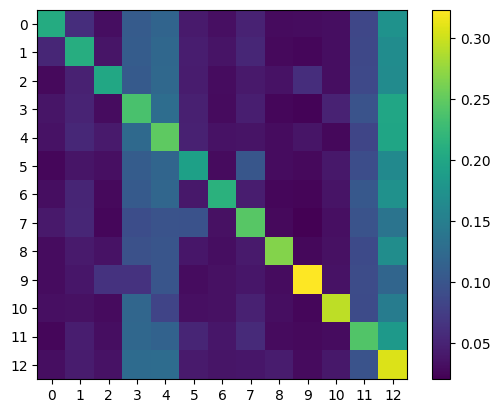

array([[0.20637425, 0.06001968, 0.03165649, 0.10761106, 0.11825953,
        0.04267813, 0.03252963, 0.049109  , 0.02971941, 0.03059786,
        0.03168177, 0.08495982, 0.17480337],
       [0.05240353, 0.20922359, 0.03782766, 0.10794889, 0.12097869,
        0.04418016, 0.03613014, 0.05282541, 0.02764983, 0.02597006,
        0.03198886, 0.08557976, 0.16729342],
       [0.02743826, 0.04856128, 0.20234833, 0.10591334, 0.12221456,
        0.04326885, 0.02993824, 0.04068926, 0.03529704, 0.05938069,
        0.03192726, 0.08707221, 0.16595067],
       [0.03696616, 0.05043668, 0.0297486 , 0.23677653, 0.12841798,
        0.04718043, 0.02904891, 0.04581267, 0.02570839, 0.02290876,
        0.04913828, 0.09801692, 0.19983969],
       [0.03528057, 0.05413678, 0.04159435, 0.12364881, 0.24827496,
        0.04760441, 0.03541237, 0.03676327, 0.03012524, 0.03776509,
        0.02658075, 0.08415478, 0.19865862],
       [0.02595015, 0.03712791, 0.03272326, 0.10847392, 0.11867696,
        0.19247629, 0.02952

In [45]:
P_c = gpcca.coarse_grained_transition_matrix
# plot P_c:
fig, ax = plt.subplots()
c = ax.imshow(P_c)
plt.xticks(np.arange(P_c.shape[1]))
plt.yticks(np.arange(P_c.shape[0]))
plt.ylim(-0.5, P_c.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show P_c matrix:
P_c

In [51]:
gpcca.coarse_grained_transition_matrix[gpcca.coarse_grained_transition_matrix < 0]

array([], dtype=float64)

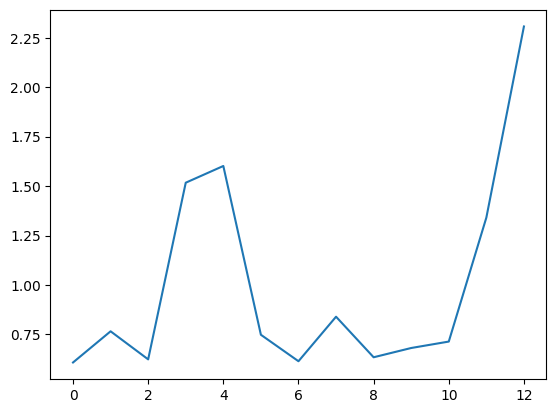

In [52]:
plt.plot(gpcca.coarse_grained_transition_matrix.sum(axis=0))